# Projeto Aplicado — Sprint 2 · RFM e Clusterização (base Olist)
**Segmentação de Clientes por Valor (RFM e Clusterização) para Otimização de Marketing e Retenção em E-commerce de Moda**

Aluno: Fábio Roberto Gomes Filho · Orientador: Marcos Prochnow · Pós-graduação em Ciência de Dados com IA (XP Educação)

| Sprint 2 | 09/11 – 15/11/2026 |
|---|---|
| R06 | Calcular Recência, Frequência e Valor por cliente |
| R07 | Gerar o escore RFM por quintis e a segmentação por regras (linha de base) |
| R08 | Pré-processar os dados para clusterização |
| R09 | Definir o número de grupos e treinar o K-Means |
| R10 | Validar os clusters |
| R11 | Interpretar e nomear os segmentos |

> Entrada: `PROCESSADOS/olist_pedidos_tratados.parquet` (Sprint 1, R03). A aplicação na base da LLVE é feita na Sprint 3 (R12), com o mesmo pipeline.

## Preparação do ambiente

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import random, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

BASE_DIR   = Path('/content/drive/MyDrive/PROJETO APLICADO CD/PROJETO APLICADO')
OUTPUT_DIR = BASE_DIR / 'PROCESSADOS'
FIG_DIR    = BASE_DIR / 'FIGURAS'
SEED = 42
random.seed(SEED); np.random.seed(SEED)

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', context='notebook')
COR, COR_DESTAQUE, COR_NEUTRA = '#2E7D5B', '#C0392B', '#9AA5B1'

def salvar(nome):
    plt.savefig(FIG_DIR / f'{nome}.png', dpi=200, bbox_inches='tight')

pedidos = pd.read_parquet(OUTPUT_DIR / 'olist_pedidos_tratados.parquet')
print(f'{len(pedidos):,} pedidos · {pedidos["customer_unique_id"].nunique():,} clientes')

Mounted at /content/drive
96,379 pedidos · 93,261 clientes


---
## R06 · Cálculo de Recência, Frequência e Valor por cliente
**Critério de aceite:** tabela RFM por cliente.

Decisões (registradas para o relatório):
| # | Decisão | Justificativa |
|---|---|---|
| S1 | **Data de referência** = dia seguinte ao último pedido da base (Olist: 30/08/2018) | Padrão da literatura; não depende da data de extração do arquivo. Na LLVE, mesma regra |
| S2 | **Recência (R)** = dias entre a última compra e a data de referência | Quanto menor, mais recente o cliente |
| S3 | **Frequência (F)** = nº de pedidos distintos do cliente; versão ordinal `F_ord` = 1, 2 ou 3+ | 97% dos clientes têm 1 pedido (achado A3); a cauda de 4 a 15 pedidos é agrupada em 3+ |
| S4 | **Valor (M)** = soma do valor pago pelo cliente (D1 da Sprint 1) | Definição clássica do RFM: receita total gerada pelo cliente |

In [2]:
DATA_REF = pedidos['order_purchase_timestamp'].max().normalize() + pd.Timedelta(days=1)

rfm = (pedidos.groupby('customer_unique_id')
       .agg(ultima_compra=('order_purchase_timestamp', 'max'),
            primeira_compra=('order_purchase_timestamp', 'min'),
            F=('order_id', 'nunique'),
            M=('valor_pago', 'sum'),
            uf=('customer_state', 'last')))
rfm['R'] = (DATA_REF - rfm['ultima_compra']).dt.days
rfm['F_ord'] = rfm['F'].clip(upper=3)
rfm['ticket_medio'] = rfm['M'] / rfm['F']
rfm = rfm[['R', 'F', 'F_ord', 'M', 'ticket_medio', 'primeira_compra', 'ultima_compra', 'uf']]

assert rfm.index.is_unique and len(rfm) == pedidos['customer_unique_id'].nunique()
assert np.isclose(rfm['M'].sum(), pedidos['valor_pago'].sum()), 'receita não confere'

print(f'Data de referência: {DATA_REF:%d/%m/%Y} · {len(rfm):,} clientes')
rfm[['R', 'F', 'M']].describe(percentiles=[.2, .4, .5, .6, .8]).T

Data de referência: 30/08/2018 · 93,261 clientes


,count,mean,std,min,20%,40%,50%,60%,80%,max
R,"93,261.00",237.46,152.56,0.00,92.00,177.00,218.00,268.00,382.00,695.00
F,"93,261.00",1.03,0.21,1.00,1.00,1.00,1.00,1.00,1.00,15.00
M,"93,261.00",161.86,195.10,9.59,55.24,87.32,107.78,132.49,208.07,"4,655.91"


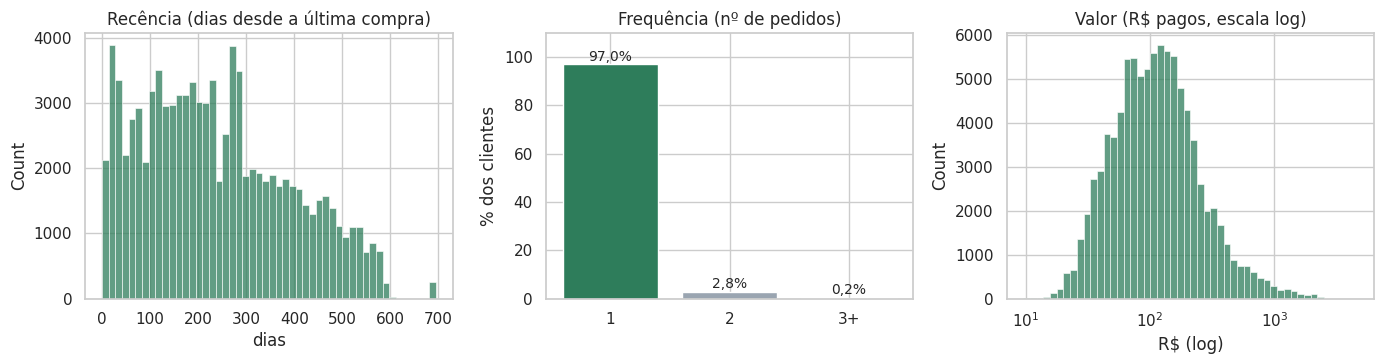

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(rfm['R'], bins=50, color=COR, ax=axes[0])
axes[0].set_title('Recência (dias desde a última compra)'); axes[0].set_xlabel('dias')

freq = rfm['F_ord'].map({1: '1', 2: '2', 3: '3+'}).value_counts(normalize=True).reindex(['1', '2', '3+']) * 100
axes[1].bar(freq.index, freq.values, color=[COR, COR_NEUTRA, COR_NEUTRA])
for i, v in enumerate(freq.values):
    axes[1].text(i, v + 1.5, f'{v:.1f}%'.replace('.', ','), ha='center', fontsize=10)
axes[1].set_ylim(0, 110); axes[1].set_title('Frequência (nº de pedidos)'); axes[1].set_ylabel('% dos clientes')

sns.histplot(rfm['M'], bins=50, log_scale=True, color=COR, ax=axes[2])
axes[2].set_title('Valor (R$ pagos, escala log)'); axes[2].set_xlabel('R$ (log)')
plt.tight_layout(); salvar('R06_distribuicao_rfm'); plt.show()

In [4]:
arq_rfm = OUTPUT_DIR / 'olist_rfm.parquet'
rfm.to_parquet(arq_rfm)
print(f'Salvo: {arq_rfm.name} · {len(rfm):,} clientes × {rfm.shape[1]} colunas')
rfm.head()

Salvo: olist_rfm.parquet · 93,261 clientes × 8 colunas


,R,F,F_ord,M,ticket_medio,primeira_compra,ultima_compra,uf
customer_unique_id,,,,,,,,
0000366f3b9a7992bf8c76cfdf3221e2,111,1,1,141.90,141.90,2018-05-10 10:56:27,2018-05-10 10:56:27,SP
0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,1,27.19,27.19,2018-05-07 11:11:27,2018-05-07 11:11:27,SP
0000f46a3911fa3c0805444483337064,537,1,1,86.22,86.22,2017-03-10 21:05:03,2017-03-10 21:05:03,SC
0000f6ccb0745a6a4b88665a16c9f078,321,1,1,43.62,43.62,2017-10-12 20:29:41,2017-10-12 20:29:41,PA
0004aac84e0df4da2b147fca70cf8255,288,1,1,196.89,196.89,2017-11-14 19:45:42,2017-11-14 19:45:42,SP


### Checklist do R06
- [x] Data de referência definida (S1) e Recência calculada em dias (S2)
- [x] Frequência por pedidos distintos e versão ordinal 1 / 2 / 3+ (S3)
- [x] Valor = soma do valor pago, com conferência da receita total (S4)
- [x] Figura `FIGURAS/R06_distribuicao_rfm.png` exportada
- [x] Tabela RFM salva em `PROCESSADOS/olist_rfm.parquet`

---
## R07 · Escore RFM por quintis e segmentação por regras (linha de base)
**Critério de aceite:** segmentos de referência.

Decisões:
| # | Decisão | Justificativa |
|---|---|---|
| S5 | Notas de **R** e **M** por quintis (1 a 5); em R, nota 5 = compra mais recente | Escore clássico do RFM. Empates resolvidos pela ordem (`rank(method='first')`) para gerar quintis de tamanho igual |
| S6 | Nota de **F** por faixas fixas: 1 pedido = 1; 2 pedidos = 3; 3+ pedidos = 5 | Quintis são impossíveis em F (os quatro cortes caem em 1 pedido) |
| S7 | **5 segmentos do projeto**, por regras aplicadas em ordem de prioridade (quadro abaixo) | Mesmos nomes do relatório e do playbook; servem de comparação para o K-Means (R10) |

| Ordem | Segmento | Regra |
|---|---|---|
| 1 | Campeões | Recomprou (F ≥ 3) **e** R ≥ 3 **e** M ≥ 4 |
| 2 | Recorrentes | Recomprou (F ≥ 3) **e** R ≥ 3 |
| 3 | Em Risco | Recomprou com R ≤ 2, **ou** compra única de alto valor (M ≥ 4) com R ≤ 3 |
| 4 | Compra Única Recente | Compra única **e** R ≥ 4 |
| 5 | Inativos | Demais clientes (compra única, antiga e de valor baixo ou médio) |

In [5]:
rfm['R_score'] = pd.qcut(rfm['R'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['M_score'] = pd.qcut(rfm['M'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['F_score'] = np.select([rfm['F'] >= 3, rfm['F'] == 2], [5, 3], default=1)
rfm['RFM_score'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)

limites = pd.DataFrame({
    'R (dias)': rfm.groupby('R_score')['R'].agg(['min', 'max']).astype(int).astype(str).agg(' – '.join, axis=1),
    'M (R$)': rfm.groupby('M_score')['M'].agg(['min', 'max']).round(2).astype(str).agg(' – '.join, axis=1),
})
limites.index.name = 'nota'
limites

,R (dias),M (R$)
nota,,
1,382 – 695,9.59 – 55.24
2,268 – 382,55.24 – 87.32
3,177 – 268,87.32 – 132.49
4,92 – 177,132.49 – 208.07
5,0 – 92,208.07 – 4655.91


In [6]:
recomprou = rfm['F_score'] >= 3
condicoes = [
    recomprou & (rfm['R_score'] >= 3) & (rfm['M_score'] >= 4),
    recomprou & (rfm['R_score'] >= 3),
    (recomprou & (rfm['R_score'] <= 2)) | (~recomprou & (rfm['M_score'] >= 4) & (rfm['R_score'] <= 3)),
    ~recomprou & (rfm['R_score'] >= 4),
]
SEGMENTOS = ['Campeões', 'Recorrentes', 'Em Risco', 'Compra Única Recente', 'Inativos']
rfm['segmento_regra'] = np.select(condicoes, SEGMENTOS[:4], default='Inativos')

perfil_regra = (rfm.groupby('segmento_regra')
    .agg(clientes=('R', 'size'), R_mediana=('R', 'median'), F_media=('F', 'mean'),
         M_mediana=('M', 'median'), receita=('M', 'sum'))
    .reindex(SEGMENTOS))
perfil_regra['% clientes'] = perfil_regra['clientes'] / perfil_regra['clientes'].sum() * 100
perfil_regra['% receita'] = perfil_regra['receita'] / perfil_regra['receita'].sum() * 100
perfil_regra

,clientes,R_mediana,F_media,M_mediana,receita,% clientes,% receita
segmento_regra,,,,,,,
Campeões,1481,129.00,2.16,269.12,"538,064.75",1.59,3.56
Recorrentes,324,135.50,2.02,100.74,"31,839.96",0.35,0.21
Em Risco,21666,314.00,1.05,206.87,"6,292,149.78",23.23,41.68
Compra Única Recente,36100,92.00,1.00,108.05,"5,793,254.88",38.71,38.38
Inativos,33690,314.00,1.00,69.61,"2,440,064.35",36.12,16.16


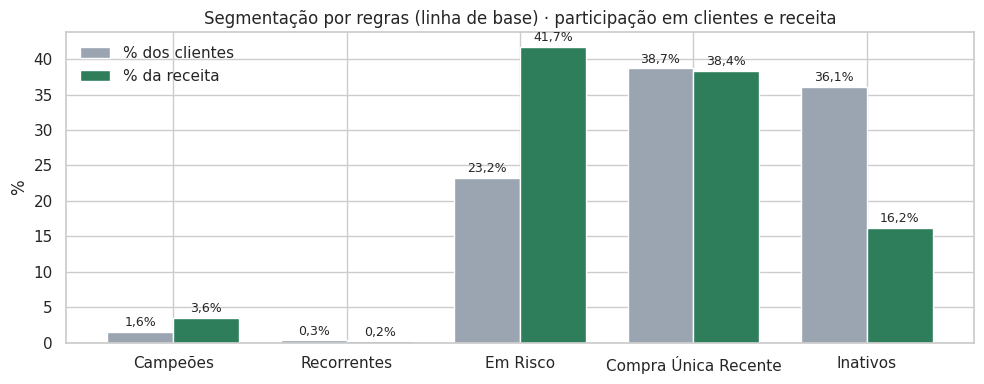

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(SEGMENTOS)); w = 0.38
ax.bar(x - w/2, perfil_regra['% clientes'], w, color=COR_NEUTRA, label='% dos clientes')
ax.bar(x + w/2, perfil_regra['% receita'], w, color=COR, label='% da receita')
for i, (a, b) in enumerate(zip(perfil_regra['% clientes'], perfil_regra['% receita'])):
    ax.text(i - w/2, a + 0.8, f'{a:.1f}%'.replace('.', ','), ha='center', fontsize=9)
    ax.text(i + w/2, b + 0.8, f'{b:.1f}%'.replace('.', ','), ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(SEGMENTOS); ax.set_ylabel('%')
ax.set_title('Segmentação por regras (linha de base) · participação em clientes e receita')
ax.legend(frameon=False)
plt.tight_layout(); salvar('R07_segmentos_regra'); plt.show()

In [8]:
rfm.to_parquet(arq_rfm)
print(f'Atualizado: {arq_rfm.name} · colunas: {list(rfm.columns)}')

Atualizado: olist_rfm.parquet · colunas: ['R', 'F', 'F_ord', 'M', 'ticket_medio', 'primeira_compra', 'ultima_compra', 'uf', 'R_score', 'M_score', 'F_score', 'RFM_score', 'segmento_regra']


### Checklist do R07
- [x] Notas de R e M por quintis e de F por faixas fixas (S5, S6)
- [x] Código RFM de 3 dígitos por cliente
- [x] 5 segmentos de referência por regras (S7), com perfil e participação na receita
- [x] Figura `FIGURAS/R07_segmentos_regra.png` exportada
- [x] Tabela RFM atualizada em `PROCESSADOS/olist_rfm.parquet`

---
## R08 · Pré-processamento para a clusterização
**Critério de aceite:** matriz de atributos pronta para modelagem.

Decisões:
| # | Decisão | Justificativa |
|---|---|---|
| S8 | Variáveis do modelo: **R** (dias), **F_ord** (1, 2, 3+) e **log(M)** | Valores contínuos preservam mais informação que as notas 1–5; com as notas, o K-Means tenderia a reproduzir as regras do R07 |
| S9 | **Logaritmo apenas em M** | M é muito assimétrico (assimetria 4,7); R tem distribuição próxima da uniforme e não precisa de transformação |
| S10 | Padronização com **StandardScaler** (média 0, desvio 1) | O K-Means usa distância euclidiana: sem padronização, R (0 a 695 dias) dominaria F e M. O RobustScaler foi descartado porque o IQR de F é zero |

In [9]:
from sklearn.preprocessing import StandardScaler
import joblib

rfm = pd.read_parquet(OUTPUT_DIR / 'olist_rfm.parquet')

FEATURES = ['R', 'F_ord', 'log_M']
X = pd.DataFrame({'R': rfm['R'], 'F_ord': rfm['F_ord'], 'log_M': np.log(rfm['M'])}, index=rfm.index)

assimetria = pd.DataFrame({
    'antes': [rfm['R'].skew(), rfm['F_ord'].skew(), rfm['M'].skew()],
    'depois': [X['R'].skew(), X['F_ord'].skew(), X['log_M'].skew()],
}, index=['R', 'F_ord', 'M → log(M)'])
display(assimetria)

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=FEATURES, index=X.index)
X_scaled.describe().T[['mean', 'std', 'min', 'max']]

,antes,depois
R,0.45,0.45
F_ord,6.30,6.30
M → log(M),4.68,0.46


,mean,std,min,max
R,0.00,1.00,-1.56,3.00
F_ord,0.00,1.00,-0.17,10.33
log_M,0.00,1.00,-3.03,4.61


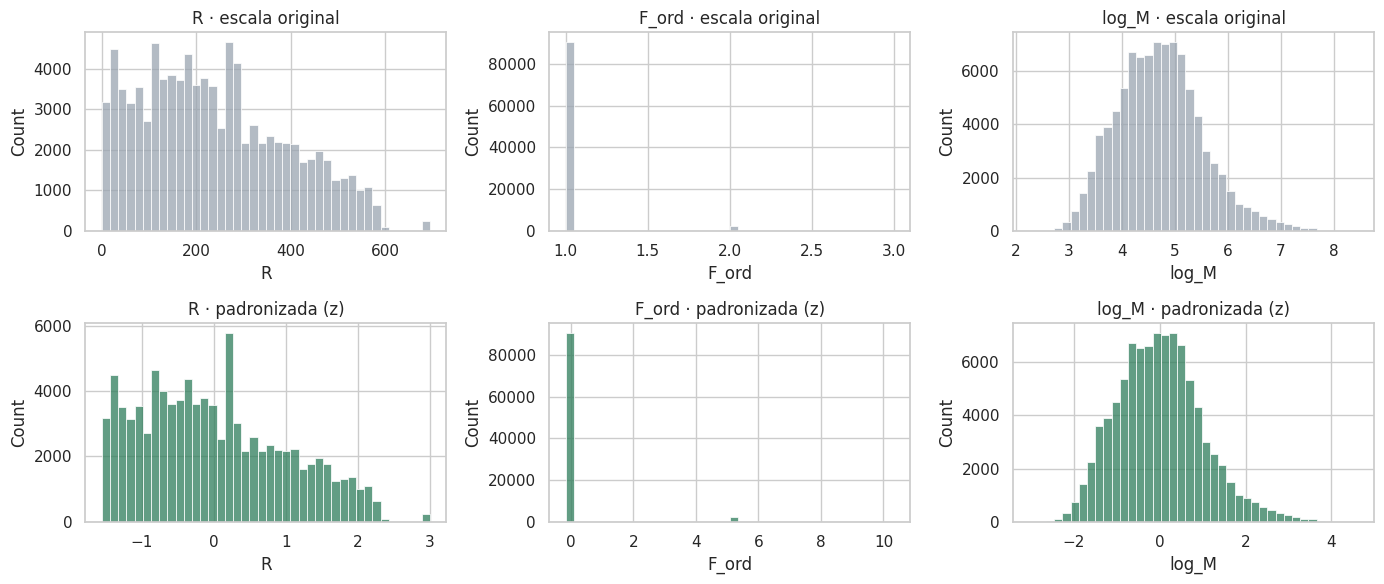

Correlação entre as variáveis do modelo:


,R,F_ord,log_M
R,1.00,-0.02,-0.01
F_ord,-0.02,1.00,0.16
log_M,-0.01,0.16,1.00


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for j, col in enumerate(FEATURES):
    sns.histplot(X[col], bins=40, color=COR_NEUTRA, ax=axes[0, j])
    axes[0, j].set_title(f'{col} · escala original')
    sns.histplot(X_scaled[col], bins=40, color=COR, ax=axes[1, j])
    axes[1, j].set_title(f'{col} · padronizada (z)')
plt.tight_layout(); salvar('R08_preprocessamento'); plt.show()

print('Correlação entre as variáveis do modelo:')
X_scaled.corr().round(2)

In [11]:
X_scaled.to_parquet(OUTPUT_DIR / 'olist_features.parquet')
joblib.dump(scaler, OUTPUT_DIR / 'olist_scaler.joblib')
print(f'Salvo: olist_features.parquet ({X_scaled.shape[0]:,} × {X_scaled.shape[1]}) e olist_scaler.joblib')

Salvo: olist_features.parquet (93,261 × 3) e olist_scaler.joblib


### Checklist do R08
- [x] Variáveis definidas: R, F_ord e log(M) (S8, S9)
- [x] Assimetria de M reduzida pela transformação logarítmica
- [x] Padronização com StandardScaler (S10), média 0 e desvio 1
- [x] Figura `FIGURAS/R08_preprocessamento.png` exportada
- [x] Matriz de atributos e scaler salvos em `PROCESSADOS`

---
## R09 · Escolha do número de grupos e treino do K-Means
**Critério de aceite:** modelo treinado com k justificado.

### 9.1 Diagnóstico de k (2 a 10)
Para cada k: inércia (método do cotovelo), coeficiente de silhueta e índice de Davies-Bouldin. A silhueta é calculada em uma **amostra aleatória de 20.000 clientes** (custo O(n²) com 93 mil clientes); os demais indicadores usam a base inteira. Metas do Objetivo SMART: 4 a 6 segmentos, nenhum com menos de 3% dos clientes, silhueta ≥ 0,35 e Davies-Bouldin ≤ 1,0.

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

AMOSTRA_SILHUETA = 20_000
rng = np.random.default_rng(SEED)
idx_amostra = rng.choice(len(X_scaled), AMOSTRA_SILHUETA, replace=False)
Xv = X_scaled.values

diagnostico = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xv)
    rot = km.labels_
    diagnostico.append({
        'k': k,
        'inércia': km.inertia_,
        'silhueta': silhouette_score(Xv[idx_amostra], rot[idx_amostra]),
        'davies_bouldin': davies_bouldin_score(Xv, rot),
        'menor grupo (%)': np.bincount(rot).min() / len(rot) * 100,
    })
diagnostico = pd.DataFrame(diagnostico).set_index('k')
diagnostico['atende metas'] = (diagnostico.index.isin([4, 5, 6]) & (diagnostico['silhueta'] >= 0.35)
                               & (diagnostico['davies_bouldin'] <= 1.0) & (diagnostico['menor grupo (%)'] >= 3))
diagnostico

,inércia,silhueta,davies_bouldin,menor grupo (%),atende metas
k,,,,,
2,"189,794.93",0.71,0.48,3.00,False
3,"125,939.79",0.36,0.92,3.00,False
4,"85,290.46",0.37,0.78,3.00,True
5,"69,980.30",0.35,0.84,3.00,True
6,"58,895.50",0.34,0.86,3.00,False
7,"50,271.40",0.36,0.77,3.00,False
8,"44,405.86",0.36,0.73,0.24,False
9,"38,908.61",0.35,0.76,0.24,False
10,"35,051.17",0.35,0.79,0.24,False


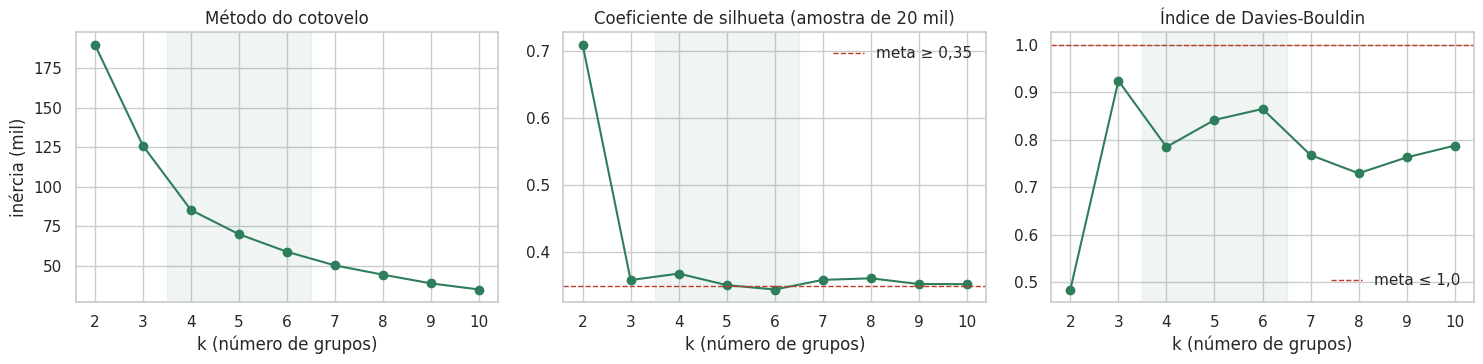

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
ks = diagnostico.index
axes[0].plot(ks, diagnostico['inércia'] / 1e3, marker='o', color=COR)
axes[0].set_title('Método do cotovelo'); axes[0].set_ylabel('inércia (mil)')
axes[1].plot(ks, diagnostico['silhueta'], marker='o', color=COR)
axes[1].axhline(0.35, color=COR_DESTAQUE, ls='--', lw=1, label='meta ≥ 0,35'); axes[1].legend(frameon=False)
axes[1].set_title('Coeficiente de silhueta (amostra de 20 mil)')
axes[2].plot(ks, diagnostico['davies_bouldin'], marker='o', color=COR)
axes[2].axhline(1.0, color=COR_DESTAQUE, ls='--', lw=1, label='meta ≤ 1,0'); axes[2].legend(frameon=False)
axes[2].set_title('Índice de Davies-Bouldin')
for ax in axes:
    ax.set_xlabel('k (número de grupos)'); ax.set_xticks(ks)
    ax.axvspan(3.5, 6.5, color=COR, alpha=0.07)
plt.tight_layout(); salvar('R09_escolha_k'); plt.show()